# Lignin valorization at one site and across a supply chain

Compare a colocated biorefinery with a network that separates biomass pretreatment, lignin conversion, and fermentation. Both cases must make at least 30 tonnes of polyhydroxyalkanoate (PHA) per operating day. The model chooses which of the legacy process routes to operate and accounts for feedstock and utility costs and coproduct sales.

## Process inputs

The legacy conversion coefficients and input prices are embedded below. Each process entry lists its stage, capital and fixed operating cost per unit of capacity, and its signed conversion coefficients. The model uses a representative operating day with 330 identical operating days per year. The distributed case preserves the three locations and moves the two intermediates between their production and use sites.

Source: [legacy lignin study at db35908](https://github.com/cacodcar/kuru/blob/db35908bd9056ef8f484c425bf2d2cb428677a83/studies/examples_old/lignin/case_study_combined.ipynb). Fixed-charge behavior was checked against Energia’s historical implementation at `0604a26ee45a564bcd83c736077944cb1c59a50d`.


In [1]:
from math import isclose

import pandas as pd
from energia import Location, Model, Process, Resource, Transport
from energia.modeling.parameters.conversion import Conversion
from gana import inf

# Commodity: maximum purchase per day, purchase price, sale price.
resources = {
    "hardwood": (2000, 78, 0),
    "softwood": (2000, 87, 0),
    "herbaceous": (2000, 70, 0),
    "glucose": (0, 0, 893.49),
    "xylose": (0, 0, 2235.86),
    "lignin": (0, 0, 0),
    "lig_mono": (0, 0, 0),
    "char": (0, 0, 118),
    "uncon_lig": (0, 0, 128),
    "pha": (0, 0, 5582.44),
    "lipid": (0, 0, 1118.27),
    "ma": (0, 0, 1395.61),
    "water": (100000000, 3.75, 0),
    "naoh": (100000000, 580.4, 0),
    "h2so4": (100000000, 104.69, 0),
    "nh3": (100000000, 462.57, 0),
    "etoh": (100000000, 820.46, 0),
    "anthraquinone": (100000000, 4643.46, 0),
    "h2": (100000000, 1778.69, 0),
    "cellulase": (100000000, 1191.97, 0),
    "cool_water": (100000000, 0.000795, 0),
    "electric": (100000000, 0.137, 0),
    "nat_gas": (100000000, 0.02, 0),
}

# Process: site stage, annual capacity cost, signed material balance.
plants = {
    "dsa_hardwood": (0, 16674.5558, {
        "hardwood": -1, "glucose": 0.4186, "xylose": 0.252, "lignin": 0.247,
        "water": -5, "h2so4": 0.009, "nh3": 0.0053, "cellulase": -0.005,
        "cool_water": -1.19, "electric": -633.33, "nat_gas": -544.43,
    }),
    "dsa_softwood": (0, 16674.5558, {
        "softwood": -1, "glucose": 0.3458, "xylose": 0.288, "lignin": 0.285,
        "water": -5, "h2so4": 0.009, "nh3": 0.0053, "cellulase": -0.005,
        "cool_water": -1.19, "electric": -633.33, "nat_gas": -544.43,
    }),
    "dsa_herbaceous": (0, 16674.5558, {
        "herbaceous": -1, "glucose": 0.4459, "xylose": 0.324, "lignin": 0.1425,
        "water": -5, "h2so4": 0.009, "nh3": 0.0053, "cellulase": -0.005,
        "cool_water": -1.19, "electric": -633.33, "nat_gas": -544.43,
    }),
    "sep_hardwood": (0, 16272.5424, {
        "hardwood": -1, "glucose": 0.3128, "xylose": 0.1624, "lignin": 0.2236,
        "water": -10, "cellulase": -0.005, "cool_water": -0.53, "electric": -819.44,
        "nat_gas": -525.05,
    }),
    "sep_softwood": (0, 16272.5424, {
        "softwood": -1, "glucose": 0.2584, "xylose": 0.1856, "lignin": 0.258,
        "water": -10, "cellulase": -0.005, "cool_water": -0.53, "electric": -819.44,
        "nat_gas": -525.05,
    }),
    "sep_herbaceous": (0, 16272.5424, {
        "herbaceous": -1, "glucose": 0.3332, "xylose": 0.2088, "lignin": 0.129,
        "water": -10, "cellulase": -0.005, "cool_water": -0.53, "electric": -819.44,
        "nat_gas": -525.05,
    }),
    "lhw_hardwood": (0, 10641.3547, {
        "hardwood": -1, "glucose": 0.4692, "xylose": 0.2184, "lignin": 0.2548,
        "water": -5, "cellulase": -0.005, "cool_water": -1.86, "electric": -866.67,
        "nat_gas": -691.65,
    }),
    "lhw_softwood": (0, 10641.3547, {
        "softwood": -1, "glucose": 0.3876, "xylose": 0.2496, "lignin": 0.294,
        "water": -5, "cellulase": -0.005, "cool_water": -1.86, "electric": -866.67,
        "nat_gas": -691.65,
    }),
    "lhw_herbaceous": (0, 10641.3547, {
        "herbaceous": -1, "glucose": 0.4998, "xylose": 0.2808, "lignin": 0.147,
        "water": -5, "cellulase": -0.005, "cool_water": -1.86, "electric": -866.67,
        "nat_gas": -691.65,
    }),
    "organosolv_hardwood": (0, 17691.5897, {
        "hardwood": -1, "glucose": 0.414, "xylose": 0.2268, "lignin": 0.2002,
        "water": -5, "h2so4": -0.0175, "etoh": -0.032, "cellulase": -0.005,
        "cool_water": -184.13, "electric": -2.18, "nat_gas": -595.24,
    }),
    "organosolv_softwood": (0, 17691.5897, {
        "softwood": -1, "glucose": 0.342, "xylose": 0.2592, "lignin": 0.231,
        "water": -5, "h2so4": -0.0175, "etoh": -0.032, "cellulase": -0.005,
        "cool_water": -184.13, "electric": -2.18, "nat_gas": -595.24,
    }),
    "organosolv_herbaceous": (0, 17691.5897, {
        "herbaceous": -1, "glucose": 0.441, "xylose": 0.2916, "lignin": 0.1155,
        "water": -5, "h2so4": -0.0175, "etoh": -0.032, "cellulase": -0.005,
        "cool_water": -184.13, "electric": -2.18, "nat_gas": -595.24,
    }),
    "afex_hardwood": (0, 16866.5622, {
        "hardwood": -1, "glucose": 0.414, "xylose": 0.2352, "lignin": 0.247,
        "water": -5, "nh3": -1, "cellulase": -0.005, "cool_water": -239.25,
        "electric": -1491.67, "nat_gas": -586.08,
    }),
    "afex_softwood": (0, 16866.5622, {
        "softwood": -1, "glucose": 0.342, "xylose": 0.2688, "lignin": 0.285,
        "water": -5, "nh3": -1, "cellulase": -0.005, "cool_water": -239.25,
        "electric": -1491.67, "nat_gas": -586.08,
    }),
    "afex_herbaceous": (0, 16866.5622, {
        "herbaceous": -1, "glucose": 0.441, "xylose": 0.3024, "lignin": 0.1425,
        "water": -5, "nh3": -1, "cellulase": -0.005, "cool_water": -239.25,
        "electric": -1491.67, "nat_gas": -586.08,
    }),
    "alkaline_hardwood": (0, 4155.1385, {
        "hardwood": -1, "glucose": 0.1702, "xylose": 0.0476, "lig_mono": 0.1222,
        "water": -5, "naoh": -0.04, "h2so4": -0.049, "anthraquinone": -0.0005,
        "cellulase": -0.005, "cool_water": -1.18, "electric": -100, "nat_gas": -289.16,
    }),
    "alkaline_softwood": (0, 4155.1385, {
        "softwood": -1, "glucose": 0.1406, "xylose": 0.0544, "lig_mono": 0.141,
        "water": -5, "naoh": -0.04, "h2so4": -0.049, "anthraquinone": -0.0005,
        "cellulase": -0.005, "cool_water": -1.18, "electric": -100, "nat_gas": -289.16,
    }),
    "alkaline_herbaceous": (0, 4155.1385, {
        "herbaceous": -1, "glucose": 0.1813, "xylose": 0.0612, "lignin": 0.0705,
        "water": -5, "naoh": -0.04, "h2so4": -0.049, "anthraquinone": -0.0005,
        "cellulase": -0.005, "cool_water": -1.18, "electric": -100, "nat_gas": -289.16,
    }),
    "bcd": (1, 4155.1385, {
        "lignin": -1, "lig_mono": 0.36, "uncon_lig": 0.47, "water": -5,
        "naoh": -0.1, "h2so4": -0.0012, "cool_water": -1.18, "electric": -100,
        "nat_gas": -289.16,
    }),
    "pyrolysis": (1, 17355.5785, {
        "lignin": -1, "lig_mono": 0.1, "char": 0.35, "cool_water": -14.12,
        "electric": -8.96,
    }),
    "hdo": (1, 21057.7019, {
        "lignin": -1, "lig_mono": 0.25, "uncon_lig": 0.04, "h2": -0.027,
        "cool_water": -5.6, "electric": -8.36, "nat_gas": -72,
    }),
    "noprocess": (1, 0, {
        "lignin": -1, "uncon_lig": 1,
    }),
    "pha_ferment": (2, 35095.1698, {
        "lig_mono": -1, "pha": 0.12, "water": -10, "cool_water": -352.22,
        "electric": -9.7, "nat_gas": -503.16,
    }),
    "lipid_ferment": (2, 20781.6927, {
        "lig_mono": -1, "lipid": 0.13, "water": -10, "cool_water": -37.22,
        "electric": -2152.78, "nat_gas": -1388.89,
    }),
    "ma_ferment": (2, 38782.2927, {
        "lig_mono": -1, "ma": 0.22, "water": -10, "cool_water": -1372.09,
        "electric": -3255.81,
    }),
}

# Fixed charges from the legacy process definitions, once per registered process/site/year.
# The source defines solvolysis but does not install it in either site list.
incidental = {
    **{f"{route}_{feed}": charge
       for route, charge in {"dsa": 53.487, "sep": 52.198, "lhw": 34.13,
                             "organosolv": 56.75, "afex": 54.1, "alkaline": 13.327}.items()
       for feed in ("hardwood", "softwood", "herbaceous")},
    "bcd": 13.327, "pyrolysis": 55.669, "hdo": 67.544, "noprocess": 0,
    "pha_ferment": 112.57, "lipid_ferment": 66.653, "ma_ferment": 124.39,
}
assert incidental.keys() == plants.keys()
incidental_per_site = sum(incidental.values())
assert isclose(incidental_per_site, 1232.129, abs_tol=1e-9)
pd.Series(incidental, name="Fixed annual incidental charge")


dsa_hardwood              53.487
dsa_softwood              53.487
dsa_herbaceous            53.487
sep_hardwood              52.198
sep_softwood              52.198
sep_herbaceous            52.198
lhw_hardwood              34.130
lhw_softwood              34.130
lhw_herbaceous            34.130
organosolv_hardwood       56.750
organosolv_softwood       56.750
organosolv_herbaceous     56.750
afex_hardwood             54.100
afex_softwood             54.100
afex_herbaceous           54.100
alkaline_hardwood         13.327
alkaline_softwood         13.327
alkaline_herbaceous       13.327
bcd                       13.327
pyrolysis                 55.669
hdo                       67.544
noprocess                  0.000
pha_ferment              112.570
lipid_ferment             66.653
ma_ferment               124.390
Name: Fixed annual incidental charge, dtype: float64

## Formulate and solve both networks

The centralized case can consume lignin intermediates at the same site. In the distributed case, lignin goes from Houston to Philadelphia and lignin monomers continue to Washington, DC. Costs and revenues are attached where the corresponding streams occur.

The legacy cost implementation charges every registered process at every location, even when the process is idle or unavailable at that location. Its location sum does not filter by the site's process list. We preserve that behavior for parity: 1,232.129 at one site and 3,696.387 across three sites. These unconditional annual constants are separate from capacity and operating costs; they are not multiplied by 330 operating days or by an activity indicator. Solvolysis is excluded, as in the original site definitions.

The final assertions compare profit against the saved Gurobi results in the source notebook, allowing 0.05 in absolute currency units for solver precision (the archived distributed solve has a 0.029 primal–dual gap).


In [2]:
def solve_chain(distributed):
    m = Model("lignin_distributed" if distributed else "lignin_centralized")
    if distributed:
        m.declare(Location, ["houston", "philadelphia", "washington"])
        sites = (m.houston, m.philadelphia, m.washington)
    else:
        m.refinery = Location()
        sites = (m.refinery,) * 3
    m.declare(Resource, list(resources))
    fixed_incidental = len(set(sites)) * incidental_per_site

    purchase_costs = []
    sale_values = []
    capacity_costs = []
    for name, (limit, price, revenue) in resources.items():
        resource = getattr(m, name)
        for site in dict.fromkeys(sites):
            if limit:
                purchase = resource.consume(site)
                _ = purchase <= limit
                purchase_costs.append((330 * price, purchase))
            if revenue:
                sale = resource.release(site)
                _ = sale >= (30 if name == "pha" and site is sites[2] else 0)
                sale_values.append((330 * revenue, sale))

    for name, (stage, annual_capacity_cost, balance) in plants.items():
        coefficients = {getattr(m, resource): value for resource, value in balance.items()}
        process = Process(Conversion.from_balance(coefficients, basis=next(iter(coefficients))))
        setattr(m, name, process)
        site = sites[stage]
        capacity = process.capacity(site)
        _ = capacity <= 1e8
        _ = process.operate(site) >= 0
        if annual_capacity_cost:
            capacity_costs.append((annual_capacity_cost, capacity))
        process.locate(site)

    if distributed:
        m.Link(m.houston, m.philadelphia, dist=200)
        m.Link(m.philadelphia, m.washington, dist=100)
        for name, commodity, link in (
            ("lignin_freight", m.lignin, m.houston - m.philadelphia),
            ("monomer_freight", m.lig_mono, m.philadelphia - m.washington),
        ):
            freight = Transport()
            setattr(m, name, freight)
            _ = freight(commodity) == 1
            _ = freight.capacity(link) <= 1e8
            _ = freight.operate(link) <= 1
            freight.locate(link)

    pha_sale = m.pha.release(sites[2])
    costs = purchase_costs + capacity_costs
    spend = fixed_incidental + sum(price * sample.V()[0] for price, sample in costs)
    earn = sum(price * sample.V()[0] for price, sample in sale_values)
    m.program.net_cost = inf(spend - earn)
    m.opt()

    spending = fixed_incidental + sum(price * sample.output(aslist=True)[0] for price, sample in costs)
    sales = sum(price * sample.output(aslist=True)[0] for price, sample in sale_values)
    assert isclose(m.program.active_objective.X, spending - sales, abs_tol=1e-5)
    pha = pha_sale.output(aslist=True)[0]
    assert pha >= 30 - 1e-6
    # Archived Gurobi profits, compared with our equivalent negative net cost.
    archived_profit = 1543447562.076 if distributed else 1543806741.072
    assert isclose(-m.program.active_objective.X, archived_profit, rel_tol=0, abs_tol=0.05)
    monomers = 0.0
    if distributed:
        monomers = m.monomer_freight.operate(m.philadelphia - m.washington).output(aslist=True)[0]
        assert pha <= 0.12 * monomers + 1e-6
    return {
        "Fixed annual incidental charges": fixed_incidental,
        "Annual spending": fixed_incidental + sum(price * sample.output(aslist=True)[0] for price, sample in costs),
        "Annual sales": sum(price * sample.output(aslist=True)[0] for price, sample in sale_values),
        "Annual net cost": m.program.active_objective.X,
        "PHA per day": pha,
        "Monomers shipped per day": monomers,
    }


results = pd.DataFrame(
    [solve_chain(False), solve_chain(True)], index=["Single site", "Three sites"]
)
results.round(2)

,Fixed annual incidental charges,Annual spending,Annual sales,Annual net cost,PHA per day,Monomers shipped per day
Single site,1232.13,5.301777e+08,2.073984e+09,-1.543807e+09,54.29,0.00
Three sites,3696.39,5.290103e+08,2.072458e+09,-1.543448e+09,54.16,451.35


## Annual cash flows

Spending is positive and sales are negative cash outflows. Diamond markers
show net cost, so a negative marker denotes profit. Annual spending already
includes the fixed incidental charges; do not add those charges again.
All three quantities are displayed in millions of the model currency.

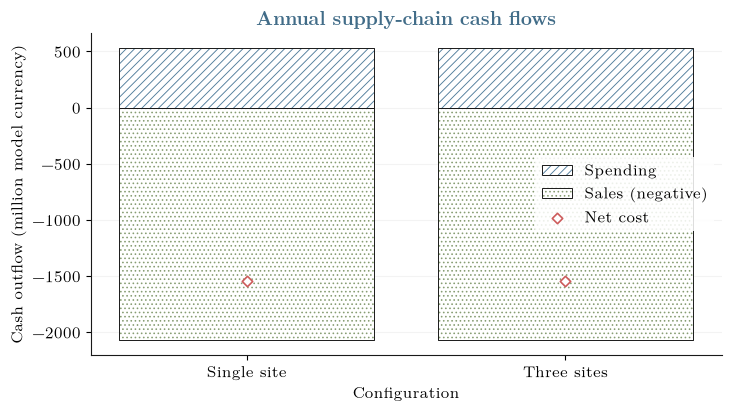

In [3]:
from gana.plotting import scatter, stacked

sites = results.index.tolist()
cash_flow = (
    stacked((results["Annual spending"] / 1e6).tolist(), x=sites, label="Spending")
    + stacked(
        (-results["Annual sales"] / 1e6).tolist(), x=sites, label="Sales (negative)"
    )
    + scatter(
        (results["Annual net cost"] / 1e6).tolist(),
        x=sites,
        label="Net cost",
        marker="D",
    )
).with_options(
    title="Annual supply-chain cash flows",
    xlabel="Configuration",
    ylabel="Cash outflow (million model currency)",
)
cash_flow.show(fig_size=(7.2, 4.0));